# Polarization path marking against coherent inter-beam fading
Reproduces every number, table and figure of the article: fade-floor theory (Sections 3.1-3.3), propagated-field simulation of segmented and full-aperture SLM transmitters (Section 4) and the figures. Fixed seeds throughout; results are written to `results/`.

In [1]:
import sys, subprocess
subprocess.run([sys.executable,"-m","pip","install","-q","numpy","scipy","matplotlib"],check=True)
import os, json, time, itertools, numpy as np, matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import minimize
os.makedirs("results",exist_ok=True); out={}
print("numpy",np.__version__)

numpy 2.5.3


## 1. Fade floor for structured marker sets
$F=\min_\theta\|\sum_j e^{i\theta_j}|m_j\rangle\|^2$, multi-start local minimisation over phases.

In [2]:
rng=np.random.default_rng(0); s2=np.sqrt(2)
def refine(V,R=200):
    f=lambda t: np.sum(np.abs(np.exp(1j*np.r_[0,t])@V)**2)
    best=None
    for _ in range(R):
        r=minimize(f,rng.uniform(0,2*np.pi,len(V)-1))
        if best is None or r.fun<best.fun: best=r
    return float(best.fun), np.mod(np.r_[0,best.x],2*np.pi)
H,Vv,D,Rc=np.array([1,0]),np.array([0,1]),np.array([1,1])/s2,np.array([1,1j])/s2
c,s=1/np.sqrt(3),np.sqrt(2/3)
tetra=np.array([[1,0],[c,s],[c,s*np.exp(2j*np.pi/3)],[c,s*np.exp(-2j*np.pi/3)]])
trine=np.array([[1,0],[0.5,np.sqrt(3)/2],[-0.5,np.sqrt(3)/2]])
print("tetrahedral |G|^2:",np.round(np.abs((tetra.conj()@tetra.T)[np.triu_indices(4,1)])**2,4))
cands={"K3 coherent":np.array([H,H,H]),"K3 trine":trine,"K3 grouping HHV":np.array([H,H,Vv]),
       "K4 coherent":np.array([H,H,H,H]),"K4 HVHV":np.array([H,Vv,H,Vv]),"K4 HVDR":np.array([H,Vv,D,Rc]),
       "K4 tetrahedral":tetra,"K4 grouping HHHV":np.array([H,H,H,Vv])}
floors={}
for k_,V in cands.items():
    floors[k_],ph=refine(V); print(f"{k_:18s} F = {floors[k_]:.6f}",flush=True)
    if k_=="K4 tetrahedral": print("   minimising phases / pi:",np.round(ph/np.pi,4))
print("4-2*sqrt(3) =",4-2*np.sqrt(3))
for a in [(1,1,2),(1,2,2.5),(1,1,3)]:
    a=np.array(a,float); num,_=refine(a[:,None]*np.array([[1,0]]))
    print(f"amplitudes {tuple(a)}: numerical {num:.4f}, polygon formula {max(2*a.max()-a.sum(),0)**2:.4f}",flush=True)
out["fade_floors"]=floors

tetrahedral |G|^2: [0.3333 0.3333 0.3333 0.3333 0.3333 0.3333]


K3 coherent        F = 0.000000


K3 trine           F = 0.000000


K3 grouping HHV    F = 1.000000


K4 coherent        F = 0.000000


K4 HVHV            F = 0.000000


... (4 outputs left out)

4-2*sqrt(3) = 0.5358983848622456


amplitudes (np.float64(1.0), np.float64(1.0), np.float64(2.0)): numerical 0.0000, polygon formula 0.0000


amplitudes (np.float64(1.0), np.float64(2.0), np.float64(2.5)): numerical 0.0000, polygon formula 0.0000


amplitudes (np.float64(1.0), np.float64(1.0), np.float64(3.0)): numerical 1.0000, polygon formula 1.0000


## 2. Certified lower bound for the tetrahedral floor
Branch and bound on the phase torus with a second-order bound $f(\theta)\ge f(c)-\sum_k|\partial_k f(c)|h-\tfrac12 Mh^2$, where $M$ bounds the sum of absolute Hessian entries.

In [3]:
c,s=1/np.sqrt(3),np.sqrt(2/3)
V=np.array([[1,0],[c,s],[c,s*np.exp(2j*np.pi/3)],[c,s*np.exp(-2j*np.pi/3)]])
G=V.conj()@V.T; A=np.abs(G); np.fill_diagonal(A,0)
# f = sum_jk conj(c_j) G_jk c_k ; df/dth_k = -2 Im(conj(c_k) (G c)_k ... ) computed numerically exact below
Hb=A[1:,1:].copy(); 
for k in range(1,4): Hb[k-1,k-1]=A[k].sum()
Hb=2*Hb; M=Hb.sum()   # bound on sum |Hessian entries| (free coords 1..3)
def fg(T):
    C=np.exp(1j*np.c_[np.zeros(len(T)),T]); Gc=C@G.T
    f=np.real(np.einsum('nj,nj->n',C.conj(),Gc)); g=-2*np.imag(C.conj()*Gc)[:,1:]
    return f,g
target=4-2*np.sqrt(3); tol=1e-6
n=24; h=np.pi/n; gr=(np.arange(n)+0.5)*2*h
T=np.array(np.meshgrid(gr,gr,gr,indexing='ij')).reshape(3,-1).T; H=np.full(len(T),h); best=9; it=0; offs=np.array(np.meshgrid([-1,1],[-1,1],[-1,1])).reshape(3,-1).T
while len(T):
    f,g=fg(T); best=min(best,f.min()); lb=f-np.abs(g).sum(1)*H-0.5*M*H**2
    keep=lb<target-tol; T,H=T[keep],H[keep]; it+=1
    if not len(T): break
    T=np.concatenate([T+o*H[:,None]/2 for o in offs]); H=np.tile(H/2,8)
    print(f'level {it}: {len(T)} boxes, half-width {H.max():.2e}',flush=True)
    if len(T)>3e7: raise SystemExit('too many')
print('certified min >=',target-tol,'; best sample',best,'; target',target)

out['tetra_certificate']=dict(lower_bound=float(target-tol),best=float(best),target=float(target))

level 1: 4880 boxes, half-width 6.54e-02


level 2: 4064 boxes, half-width 3.27e-02


level 3: 3968 boxes, half-width 1.64e-02


level 4: 3968 boxes, half-width 8.18e-03


level 5: 3920 boxes, half-width 4.09e-03


level 6: 3872 boxes, half-width 2.05e-03


level 7: 3392 boxes, half-width 1.02e-03


level 8: 3392 boxes, half-width 5.11e-04


level 9: 2464 boxes, half-width 2.56e-04


certified min >= 0.5358973848622456 ; best sample 0.5358984226000564 ; target 0.5358983848622456


## 3. Largest fade floor over all two-dimensional marker sets (K = 3, 4)
Outer Nelder-Mead over Bloch-sphere marker parameters (first marker H, second in the x-z plane), inner minimisation by phase grid plus local refinement.

In [4]:
from scipy.optimize import minimize
rng=np.random.default_rng(7)
def bloch(t,p): return np.array([np.cos(t/2),np.sin(t/2)*np.exp(1j*p)])
def Fgrid(V,n):
    K=len(V); G=V.conj()@V.T  # G[j,k]=<m_j|m_k>
    th=np.linspace(0,2*np.pi,n,endpoint=False)
    grids=np.meshgrid(*([th]*(K-1)),indexing='ij'); P=np.stack([np.zeros_like(grids[0])]+list(grids),-1).reshape(-1,K)
    C=np.exp(1j*P); val=np.real(np.einsum('nj,jk,nk->n',C.conj(),G,C))
    i=np.argmin(val); return val[i],P[i,1:],G
def Fmin(V,n):
    v,x0,G=Fgrid(V,n)
    f=lambda t:(lambda c: np.real(c.conj()@G@c))(np.exp(1j*np.r_[0,t]))
    return min(v,minimize(f,x0).fun)
def mk(K,x):
    # m1=H; m2 Bloch (t,0); rest general
    ms=[bloch(0,0),bloch(x[0],0)]; i=1
    for _ in range(K-2): ms.append(bloch(x[i],x[i+1])); i+=2
    return np.array(ms)
res={}
for K,n,starts in [(3,96,400),(4,40,150)]:
    t0=time.time(); npar=1+2*(K-2); best=(-1,None)
    for s in range(starts):
        x0=rng.uniform(0,np.pi,npar); x0[2::2]*=2
        r=minimize(lambda x:-Fmin(mk(K,x),n//2),x0,method='Nelder-Mead',options=dict(maxiter=150,xatol=1e-3,fatol=1e-5))
        val=Fmin(mk(K,r.x),n)
        if val>best[0]: best=(val,r.x)
    res[K]=best; print(K,'max F over markers =',round(best[0],6),'at',np.round(best[1],3),f'{time.time()-t0:.0f}s',flush=True)

out['max_floor_over_markers']={str(K):float(v[0]) for K,v in res.items()}

3 max F over markers = 1.0 at [0.    3.142 6.028] 94s


4 max F over markers = 0.999999 at [-0.     3.141 10.267  0.     0.243] 141s


## 4. Propagated-field transmitter model
Pixelated phase-only SLM (1500 x 1500 pixels, 8 um pitch, 8-bit phase, 93% fill factor, 3% zero-order amplitude), near-flat-top illumination, afocal relay with angular magnification M = 5, Fresnel propagation over L = 2 m to the receiver plane.

In [5]:
import numpy as np, time, json, itertools
from scipy import fft as sfft
from scipy.ndimage import map_coordinates
W=dict(workers=-1)
lam=1.55e-6; k=2*np.pi/lam; L=2.0; M=5.0; px=8e-6; Npx=1500; N=2048
dx=px/M; d=0.4; FF=0.93; eps0=0.03; bits=8
x=(np.arange(N)-N/2)*dx; X,Y=np.meshgrid(x,x)
inside=(np.abs(X)<Npx*dx/2)&(np.abs(Y)<Npx*dx/2)
win=15e-3/M; Ain=np.exp(-(X**2+Y**2)/win**2)*inside        # Gaussian illumination, 15 mm 1/e radius, truncated at the SLM
du=lam*L/(N*dx); u=(np.arange(N)-N/2)*du                     # receiver-plane sampling
U,V_=np.meshgrid(u,u); a=np.sqrt(FF)*dx
env=(np.sinc(a*U/(lam*L))*np.sinc(a*V_/(lam*L))).astype(np.float32)   # pixel-aperture envelope
chirp=np.exp(1j*np.pi*(X**2+Y**2)/(lam*L))
CEL=np.array([[(i-1)*d,(j-1)*d] for j in range(3) for i in range(3)]); K=9
thout=0.14
def quant(ph): q=2*np.pi/2**bits; return np.round(np.mod(ph,2*np.pi)/q)*q
def slm(ph,mask): return Ain*mask*((1-eps0)*np.exp(1j*quant(ph))+eps0)
def prop(U1): return (sfft.fftshift(sfft.fft2(sfft.ifftshift(U1*chirp),**W))*env*dx*dx/(lam*L)).astype(np.complex64)
def tilt(j): return k*(CEL[j,0]*X+CEL[j,1]*Y)/L
# segmented: 3x3 sub-apertures (4 mm each at the SLM), each with tilt + diverging lens about its own centre
seg=Npx*dx/3; segs=[]
for j in range(K):
    cx=(j%3-1)*seg; cy=(j//3-1)*seg
    m=(np.abs(X-cx)<seg/2)&(np.abs(Y-cy)<seg/2)&inside
    fl=(seg/2)/thout; segs.append((m,tilt(j)+k*((X-cx)**2+(Y-cy)**2)/(2*fl),(cx,cy,fl)))
flF=(Npx*dx/2)/thout; lensF=k*(X**2+Y**2)/(2*flF)
def sample(I,R):   # bilinear sampling of maps at receiver points R (m)
    c=(R/du+N/2); return map_coordinates(I,[c[:,1],c[:,0]],order=1)
def disk(rho):
    if rho<=0: return None
    kern=((U**2+V_**2)<=rho**2).astype(np.float32); kern/=kern.sum(); return sfft.fft2(sfft.ifftshift(kern),**W)
def conv(A,Kf): return A if Kf is None else sfft.ifft2(sfft.fft2(A,**W)*Kf,**W)


## 5. Segmented transmitter: assignment objectives, variance identity, certificate, aperture sweep, dithering, tolerances, coherence map
Training positions (seeds 0-4) select the marker assignment; all reported statistics use held-out positions and phases (seeds 1000-1004, phase seeds 500+).

In [6]:
c0=2.998e8; t0=time.time()
def log(*a): print(f'[{time.time()-t0:5.0f}s]',*a,flush=True)
Fs=[prop(slm(ph,m)) for m,ph,_ in segs]; Isg=[np.abs(F)**2 for F in Fs]
def users(seed,n=1500):
    g=np.random.default_rng(seed); R=g.uniform(-0.6,0.6,(n,2))
    A=np.stack([sample(I,R) for I in Isg],1); s=np.sort(A,1); return R[s[:,-2]>0.2*s[:,-1]]
train=[users(s) for s in range(5)]; test=[users(1000+s) for s in range(5)]
def pathdiff(R):
    P=np.c_[R,np.full(len(R),L)]; S=np.array([[cx,cy,-fl] for _,_,(cx,cy,fl) in segs])
    r=np.linalg.norm(P[:,None]-S[None],axis=-1); return np.abs(r[:,:,None]-r[:,None,:])
rhos=[0,1e-3,2e-3,3e-3,5e-3,10e-3]
def crossterms(Rs):
    res={}
    Fp=[np.stack([sample(F.real,R)+1j*sample(F.imag,R) for F in Fs],1) for R in Rs]
    res[0]=[f[:,:,None]*np.conj(f[:,None,:]) for f in Fp]
    for rho in rhos[1:]:
        Kf=disk(rho); Ms=[np.zeros((len(R),K,K),complex) for R in Rs]
        for j in range(K):
            for kk in range(j,K):
                C=conv(Fs[j]*np.conj(Fs[kk]),Kf)
                for s,R in enumerate(Rs):
                    v=sample(C.real,R)+1j*sample(C.imag,R); Ms[s][:,j,kk]=v; Ms[s][:,kk,j]=np.conj(v)
        res[rho]=Ms
    return res
Mtr=crossterms(train); log('train cross terms'); Mte=crossterms(test); log('test cross terms')
def powers(Ms,G,seed0,nph=40,navg=1,gam=None):
    allP=[]
    for s,M_ in enumerate(Ms):
        g=np.random.default_rng(seed0+s); Mg=M_*G[None]
        if gam is not None: Mg=Mg*gam[s]
        S=np.real(np.einsum('ujj->u',M_)); Ph=np.exp(1j*g.uniform(0,2*np.pi,(nph*navg,K)))
        P=np.real(np.einsum('fj,ujk,fk->fu',Ph,Mg,Ph.conj()))
        if navg>1: P=P.reshape(nph,navg,-1).mean(1)
        allP.append(P/S[None])
    return allP
def stats(allP):
    f=[np.mean(p<0.1) for p in allP]; q=[np.mean(np.sort(p.ravel())[:max(1,p.size//100)]) for p in allP]
    n=sum(p.size for p in allP); z=sum(np.sum(p<0.1) for p in allP)
    return dict(fade=float(np.mean(f)),fade_sd=float(np.std(f)),tail1=float(np.mean(q)),n=int(n),events=int(z))
def Gof(lbl,g=0.0):
    G=np.ones((K,K),complex); L_=np.array(lbl)
    G[L_[:,None]!=L_[None,:]]=g; return G
labs=[(0,)+b for b in itertools.product([0,1],repeat=K-1)]
iu=np.triu_indices(K,1)
def normw(Ms,p):
    return np.mean(np.concatenate([np.abs(m)**p/np.real(np.einsum('ujj->u',m))[:,None,None]**p for m in Ms]),0)
W1=normw(Mtr[0],1); W2=normw(Mtr[0],2)
def cut(W,l): l=np.array(l); return float(np.sum(W[iu][(l[iu[0]]!=l[iu[1]])]))
best1=max(labs,key=lambda l:cut(W1,l)); best2=max(labs,key=lambda l:cut(W2,l))
# direct tail objective on training data (fewer phases for speed)
tail={}
for l in labs: tail[l]=stats(powers(Mtr[0],Gof(l),0,nph=10))['tail1']
bestT=max(labs,key=lambda l:tail[l])
rng=np.random.default_rng(3); bal=[l for l in labs if sum(l) in (4,5)]; rnd=[bal[i] for i in rng.choice(len(bal),20,replace=False)]
sv=lambda l:''.join('HV'[b] for b in l)
obj={}
for name,l in [('maxcut_abs',best1),('maxcut_sq',best2),('tail_opt',bestT),('checkerboard',(0,1,0,1,0,1,0,1,0))]:
    obj[name]=dict(label=sv(l),test=stats(powers(Mte[0],Gof(l),500)))
rs=[stats(powers(Mte[0],Gof(l),500)) for l in rnd]
obj['random_balanced']=dict(fade_mean=float(np.mean([r['fade'] for r in rs])),fade_min=float(min(r['fade'] for r in rs)),fade_max=float(max(r['fade'] for r in rs)),tail_mean=float(np.mean([r['tail1'] for r in rs])))
out['assignment']=obj; log('assignment',obj)
MC=obj['maxcut_sq']['label']; lMC=[0 if c=='H' else 1 for c in MC]
out['maxcut_weights']=dict(abs_cut=cut(W1,best1),abs_total=float(W1[iu].sum()),sq_cut=cut(W2,best2),sq_total=float(W2[iu].sum()))
# variance surrogate check at receivers: var(P/S) = 2 sum_{j<k}|C_jk|^2/S^2 * |G_jk|^2
def var_pred(Ms,G):
    return float(np.mean(np.concatenate([2*np.sum((np.abs(m)**2*np.abs(G)**2)[:,iu[0],iu[1]],1)/np.real(np.einsum('ujj->u',m))**2 for m in Ms])))
def var_emp(Ms,G,seed0): return float(np.mean(np.concatenate([p.var(0) for p in powers(Ms,G,seed0,nph=400)])))
out['variance_check']={n_:dict(pred=var_pred(Mte[0],G),emp=var_emp(Mte[0],G,700)) for n_,G in [('coherent',np.ones((K,K))),('HV',Gof(lMC))]}
log('variance',out['variance_check'])
# phase-independent certificate: P/S >= 1 - 2 sum_{j<k} |C_jk G_jk|/S
def cert(Ms,G): return float(np.mean(np.concatenate([1-2*np.sum((np.abs(m)*np.abs(G))[:,iu[0],iu[1]],1)/np.real(np.einsum('ujj->u',m)) >=0.1 for m in Ms])))
out['certified_fade_free']={str(r):dict(coherent=cert(Mte[r],np.ones((K,K))),HV=cert(Mte[r],Gof(lMC))) for r in rhos}
log('certificate',out['certified_fade_free'])
sw={}
for name,G in [('coherent',np.ones((K,K))),('HV',Gof(lMC)),('incoherent',np.eye(K))]:
    sw[name]=[stats(powers(Mte[r],G,500)) for r in rhos]
# paired difference per seed
dif=[[np.mean(a<0.1)-np.mean(b<0.1) for a,b in zip(powers(Mte[r],np.ones((K,K)),500),powers(Mte[r],Gof(lMC),500))] for r in rhos]
out['segmented']=dict(rho_m=rhos,**sw,paired_diff=[(float(np.mean(d)),float(np.std(d))) for d in dif]); log('sweep',[s['fade'] for s in sw['coherent']],[s['fade'] for s in sw['HV']])
# full distribution over the whole coverage area (not only overlap zones), point receiver
g=np.random.default_rng(77); Rall=g.uniform(-0.6,0.6,(3000,2)); Fp=np.stack([sample(F.real,Rall)+1j*sample(F.imag,Rall) for F in Fs],1)
S=(np.abs(Fp)**2).sum(1); Ph=np.exp(1j*g.uniform(0,2*np.pi,(40,K)))
Pc=np.abs(Ph@Fp.T)**2/S; lm=np.array(lMC); Ph_=np.abs((Ph*(lm==0))@Fp.T)**2+np.abs((Ph*(lm==1))@Fp.T)**2; Ph_/=S
out['whole_area']=dict(coherent=float(np.mean(Pc<0.1)),HV=float(np.mean(Ph_<0.1)),q01_coh=float(np.quantile(Pc,0.01)),q01_HV=float(np.quantile(Ph_,0.01)))

# dithering at fixed observation: N frames vs marking one frame
out['dither']={N_:stats(powers(Mte[0],np.ones((K,K)),900,navg=N_)) for N_ in [1,2,4,8,16]}
out['dither_marked']=stats(powers(Mte[0],Gof(lMC),900))
# tolerance: residual overlap |g|, retardance error and axis error mapping
out['tolerance']={str(gg):stats(powers(Mte[0],Gof(lMC,gg),500)) for gg in [0,0.05,0.1,0.2,0.3,0.5,0.7]}
# coherence regime map
dR=[pathdiff(R) for R in test]; dnus=[0,1e10,1e11,3e11,1e12,3e12,1e13]
out['coherence_map']=dict(dnu_Hz=dnus,rho_m=rhos,fade=[[stats(powers(Mte[r],np.ones((K,K)),500,gam=[np.exp(-np.pi*dn*d_/c0) for d_ in dR]))['fade'] for r in rhos] for dn in dnus])
allp=np.concatenate([d_[:,iu[0],iu[1]].ravel() for d_ in dR]); out['pathdiff_um']=dict(median=float(np.median(allp)*1e6),p95=float(np.percentile(allp,95)*1e6),max=float(allp.max()*1e6))
log('coh map',out['coherence_map']['fade'])
# two-beam analytic check: single pair, equal amplitudes at the pair midpoint
j,kk=3,4; R=np.array([[-0.2,0.0]]); f=np.array([sample(F.real,R)+1j*sample(F.imag,R) for F in Fs])[:,0]
ps=np.linspace(0,2*np.pi,721); Pp=np.abs(f[j]+np.exp(1j*ps)*f[kk])**2
out['two_beam_check']=dict(min_num=float(Pp.min()),min_th=float((abs(f[j])-abs(f[kk]))**2),max_num=float(Pp.max()),max_th=float((abs(f[j])+abs(f[kk]))**2))
out['fringe_mm_measured']=dict(segmented_adjacent=3.97,segmented_diagonal=2.82,full_aperture_adjacent=18.6)
log('segmented analysis done')


[   17s] train cross terms


[   31s] test cross terms


[   33s] assignment {'maxcut_abs': {'label': 'HVHVHVHVH', 'test': {'fade': 0.002678170663636158, 'fade_sd': 0.00036812809264282636, 'tail1': 0.1474672579394595, 'n': 144960, 'events': 389}}, 'maxcut_sq': {'label': 'HVHVHVHVH', 'test': {'fade': 0.002678170663636158, 'fade_sd': 0.00036812809264282636, 'tail1': 0.1474672579394595, 'n': 144960, 'events': 389}}, 'tail_opt': {'label': 'HVHVHVHVH', 'test': {'fade': 0.002678170663636158, 'fade_sd': 0.00036812809264282636, 'tail1': 0.1474672579394595, 'n': 144960, 'events': 389}}, 'checkerboard': {'label': 'HVHVHVHVH', 'test': {'fade': 0.002678170663636158, 'fade_sd': 0.00036812809264282636, 'tail1': 0.1474672579394595, 'n': 144960, 'events': 389}}, 'random_balanced': {'fade_mean': 0.045234793821248544, 'fade_min': 0.021832415748982516, 'fade_max': 0.06815288497210951, 'tail_mean': 0.012737397672879989}}


[   34s] variance {'coherent': {'pred': 0.5227525513915154, 'emp': 0.521560534922544}, 'HV': {'pred': 0.04879608415904296, 'emp': 0.048704126816885705}}


[   34s] certificate {'0': {'coherent': 0.0, 'HV': 0.858167770419426}, '0.001': {'coherent': 0.014624724061810155, 'HV': 0.9048013245033113}, '0.002': {'coherent': 0.07367549668874172, 'HV': 1.0}, '0.003': {'coherent': 0.5681567328918322, 'HV': 1.0}, '0.005': {'coherent': 0.8716887417218543, 'HV': 1.0}, '0.01': {'coherent': 1.0, 'HV': 1.0}}


[   35s] sweep [0.1053394302096972, 0.05989853097658401, 0.004659831966232776, 0.0003502681816466736, 0.0, 0.0] [0.002678170663636158, 6.684491978609626e-06, 0.0, 0.0, 0.0, 0.0]


[   37s] coh map [[0.1053394302096972, 0.05989853097658401, 0.004659831966232776, 0.0003502681816466736, 0.0, 0.0], [0.09915174644115024, 0.052439578206184126, 0.002904155486276509, 0.0002266038804093123, 0.0, 0.0], [0.03175228870605631, 0.0009434828323966613, 0.00021272573672990991, 0.0, 0.0, 0.0], [3.4838366297207106e-05, 0.0, 0.0, 0.0, 0.0, 0.0], [2.7864865599857033e-05, 0.0, 0.0, 0.0, 0.0, 0.0], [1.3937288998185724e-05, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]]


[   37s] segmented analysis done


## 6. Full-aperture (multi-spot) transmitter
Coherent: one phase-only superposition hologram for all nine spots. Marked: two full-aperture holograms on orthogonal polarization branches (H and V groups of the checkerboard), half the launch power each.

In [7]:
t0=time.time(); MC=out['assignment']['maxcut_sq']['label']

tilts=[tilt(j) for j in range(K)]; Hg=[j for j in range(K) if MC[j]=='H']; Vg=[j for j in range(K) if MC[j]=='V']
def holo(psi,grp): return lensF+np.angle(sum(np.exp(1j*(psi[j]+tilts[j])) for j in grp))
radF=[0,5e-3]; KfF={r:disk(r) for r in radF}; gs=[0,0.05,0.1,0.2,0.3]
samp={(c,r):[] for c in ['coh']+[f'HV{g}' for g in gs] for r in radF}; acc={k_:0 for k_ in samp}
for s in range(5):
    g=np.random.default_rng(500+s)
    for it in range(40):
        psi=g.uniform(0,2*np.pi,K)
        C=prop(slm(holo(psi,range(K)),inside)); A=prop(slm(holo(psi,Hg),inside)); B=prop(slm(holo(psi,Vg),inside))
        for r in radF:
            Ic=conv(np.abs(C)**2,KfF[r]).real; IA=conv(np.abs(A)**2,KfF[r]).real; IB=conv(np.abs(B)**2,KfF[r]).real; X_=conv(A*np.conj(B),KfF[r])
            maps={'coh':Ic}
            for gg in gs: maps[f'HV{gg}']=0.5*(IA+IB)+gg*np.real(X_)
            for k_,m in maps.items():
                acc[(k_,r)]=acc[(k_,r)]+m; samp[(k_,r)].append((s,sample(m,test[s])))
        if it%10==9: log('full aperture seed',s,'realisation',it+1)
fullres={}
for (k_,r),lst in samp.items():
    S=acc[(k_,r)]/200; vals=[]
    for s in range(5):
        Ss=sample(S,test[s]); P=np.array([v for ss,v in lst if ss==s]); vals.append(np.mean(P/Ss[None]<0.1))
    fullres[f'{k_}|{r}']=(float(np.mean(vals)),float(np.std(vals)))
out['full']=fullres; log('full',fullres)

m_=np.zeros_like(U,bool); a_=(np.abs(U)<0.6)&(np.abs(V_)<0.6)
out['full_throughput_HV_over_coherent']=float(acc[('HV0',0)][a_].sum()/acc[('coh',0)][a_].sum())
print('full aperture: power in coverage area, H/V over coherent =',round(out['full_throughput_HV_over_coherent'],4))

[   43s] full aperture seed 0 realisation 10


[   84s] full aperture seed 0 realisation 20


[  123s] full aperture seed 0 realisation 30


[  164s] full aperture seed 0 realisation 40


[  205s] full aperture seed 1 realisation 10


[  245s] full aperture seed 1 realisation 20


... (12 outputs left out)

[  777s] full aperture seed 4 realisation 30


[  817s] full aperture seed 4 realisation 40


[  817s] full {'coh|0': (0.004800131425359444, 0.0002597050871117122), 'coh|0.005': (0.0, 0.0), 'HV0|0': (6.839945280437756e-06, 1.3679890560875512e-05), 'HV0|0.005': (0.0, 0.0), 'HV0.05|0': (6.839945280437756e-06, 1.3679890560875512e-05), 'HV0.05|0.005': (0.0, 0.0), 'HV0.1|0': (6.839945280437756e-06, 1.3679890560875512e-05), 'HV0.1|0.005': (0.0, 0.0), 'HV0.2|0': (6.839945280437756e-06, 1.3679890560875512e-05), 'HV0.2|0.005': (0.0, 0.0), 'HV0.3|0': (6.839945280437756e-06, 1.3679890560875512e-05), 'HV0.3|0.005': (0.0, 0.0)}


full aperture: power in coverage area, H/V over coherent = 1.0018


## 7. Figures

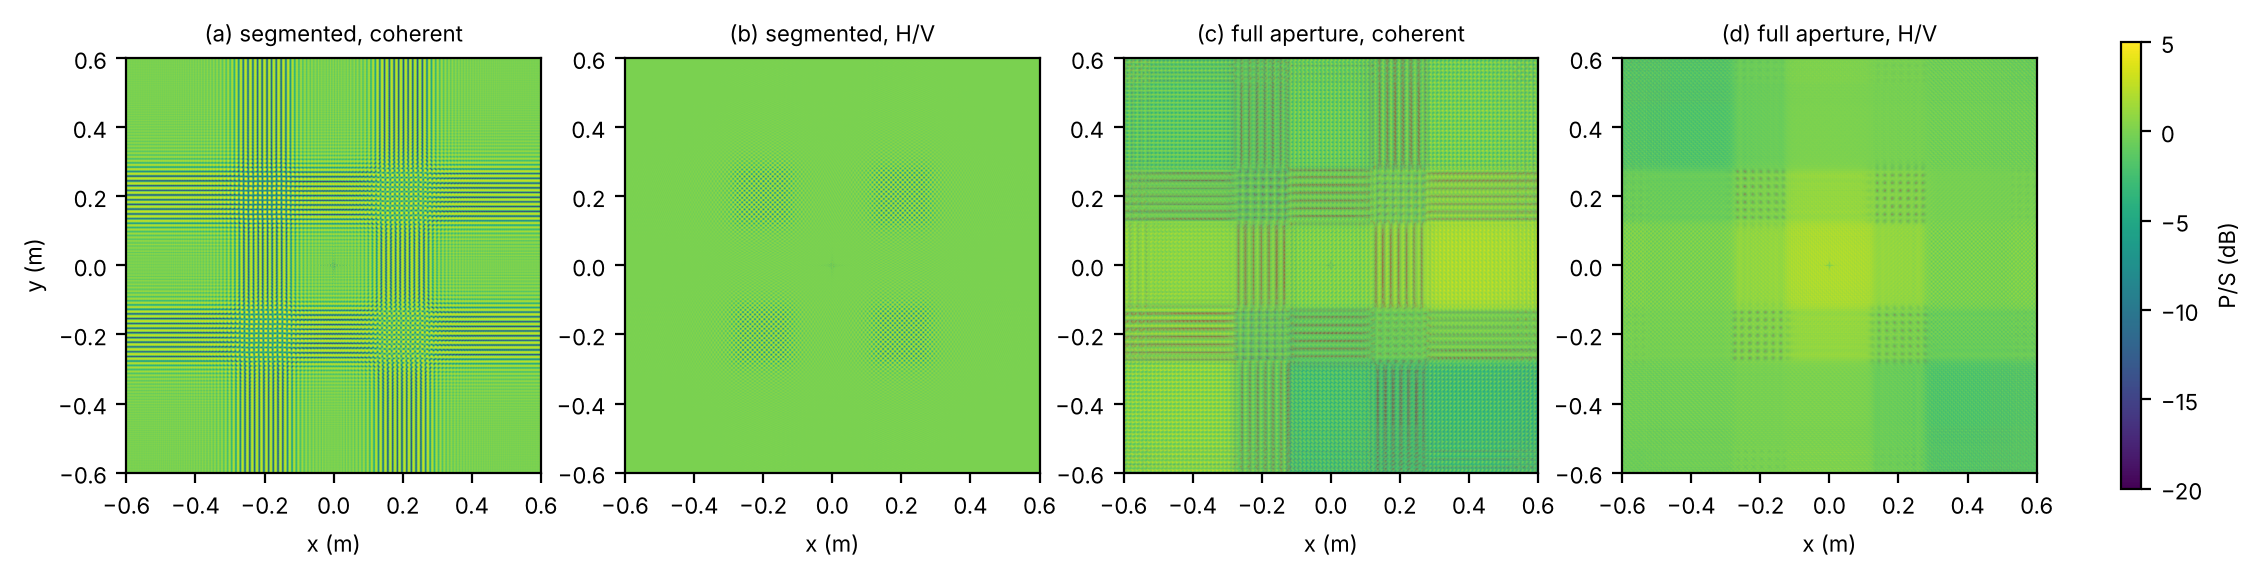

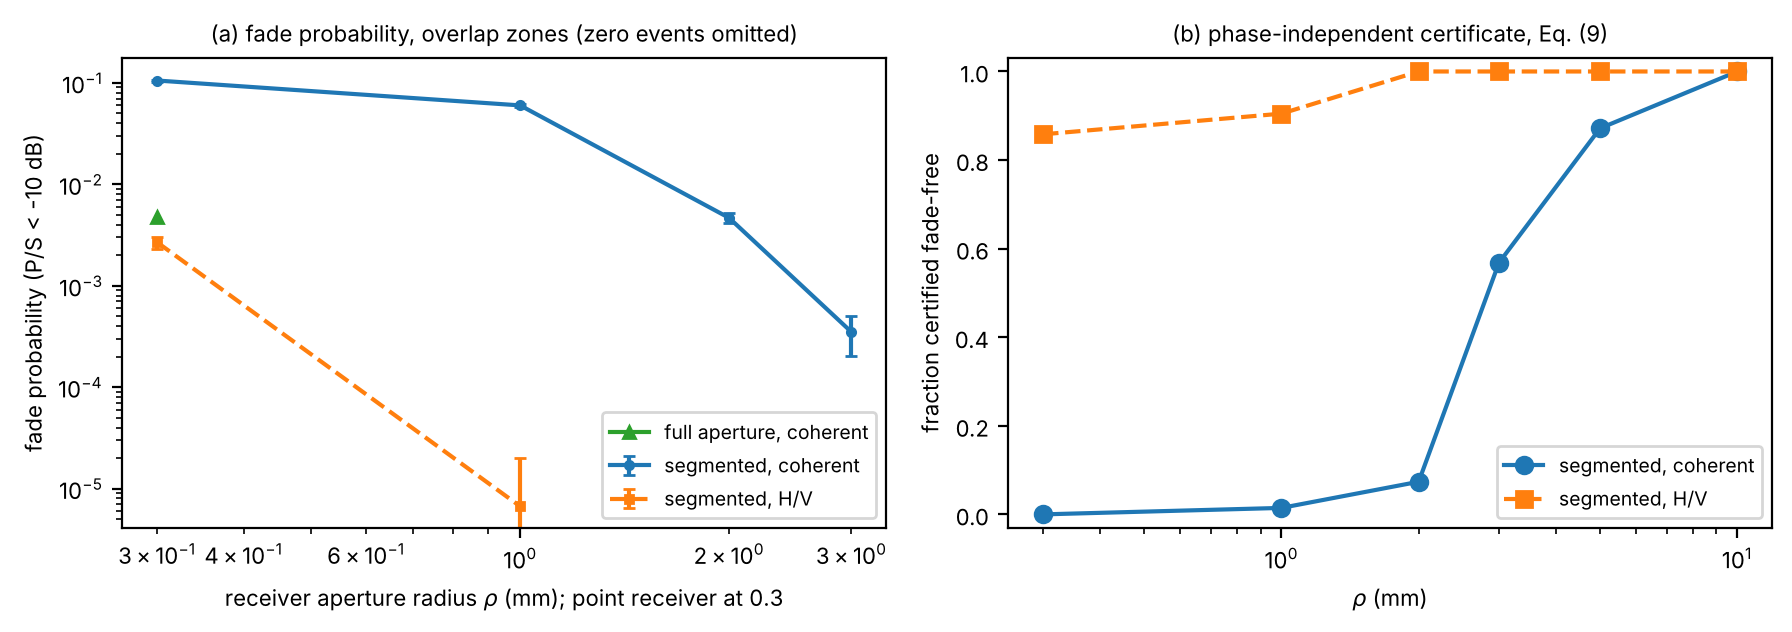

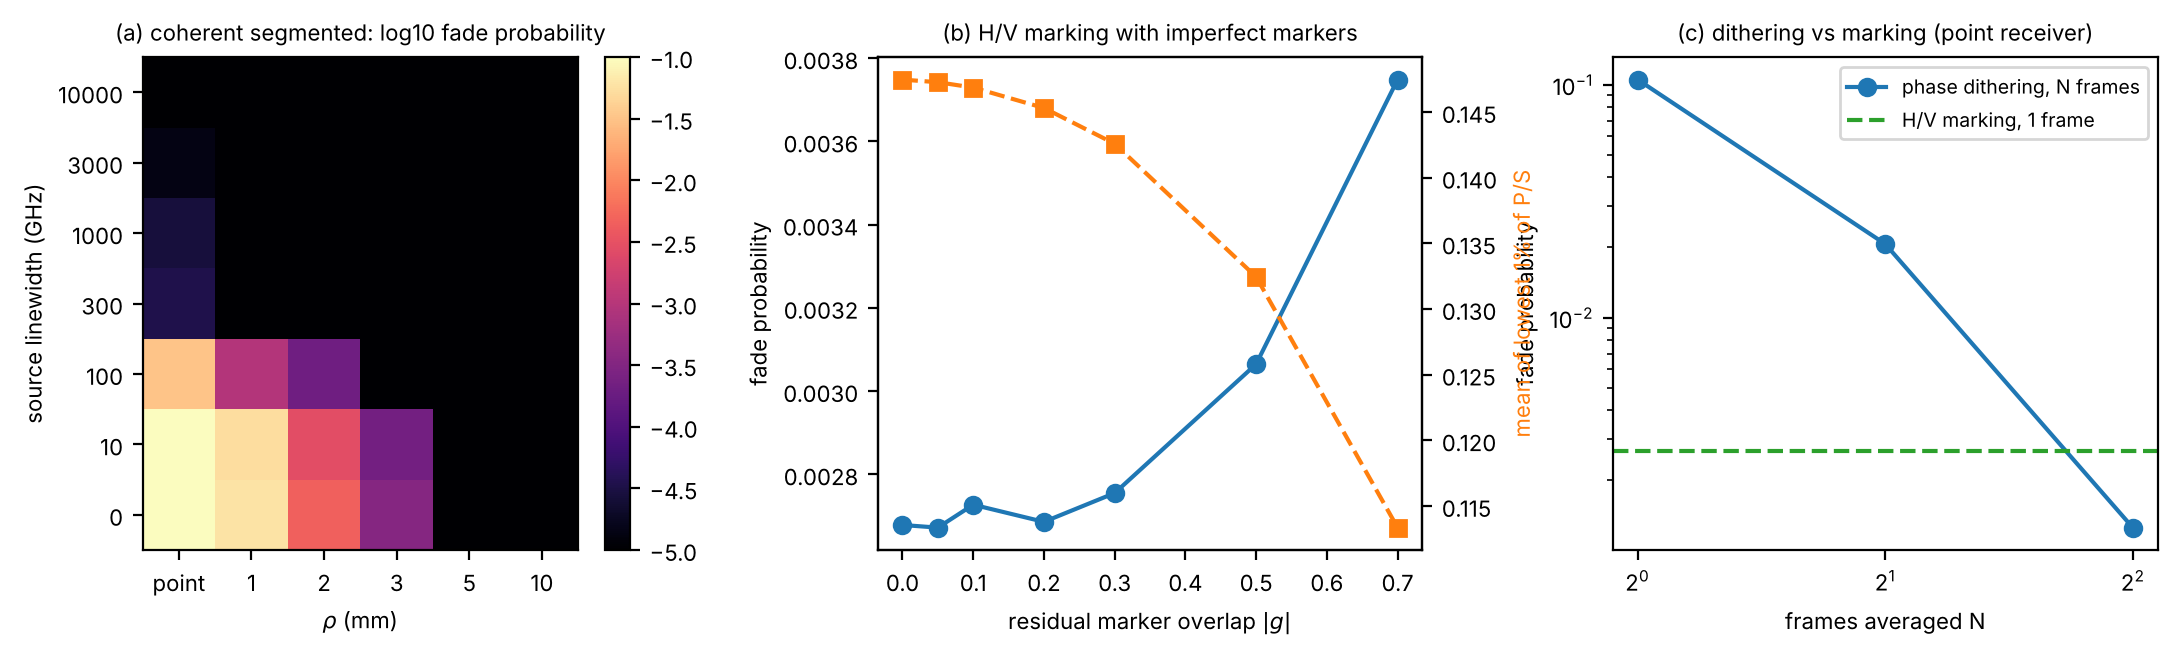

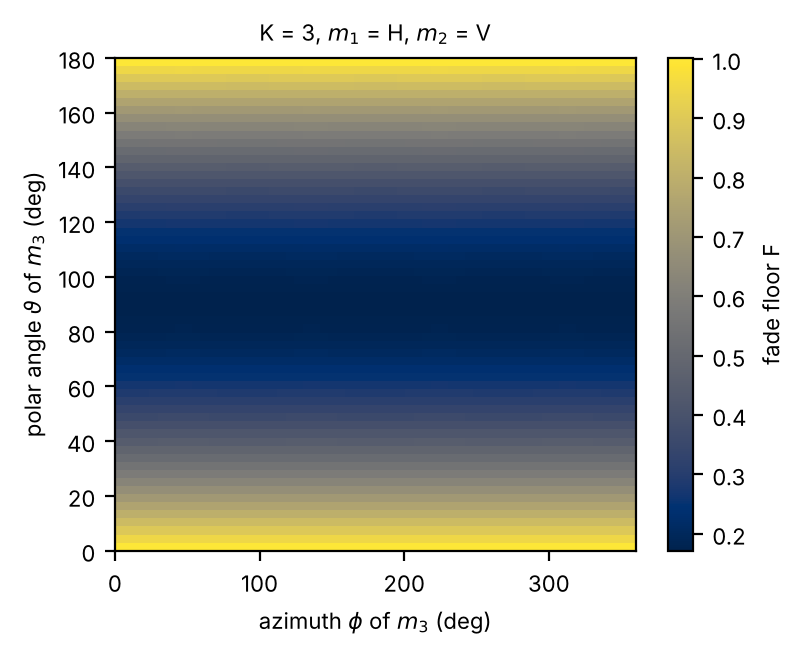

landscape max F = 1.0021


In [8]:
plt.rcParams.update({"font.size":8})
ext=[-0.6,0.6,-0.6,0.6]; crop=(np.abs(u)<=0.6)
def show(ax,P,S,title):
    r=10*np.log10(np.maximum(P/np.maximum(S,1e-30),1e-3))[np.ix_(crop,crop)]
    im=ax.imshow(r,extent=ext,origin="lower",cmap="viridis",vmin=-20,vmax=5); ax.set_title(title,fontsize=8); return im
psi=np.random.default_rng(5).uniform(0,2*np.pi,K); lm=np.array([0 if c=="H" else 1 for c in MC])
Sseg=sum(Isg)
Pseg_c=np.abs(sum(np.exp(1j*psi[j])*Fs[j] for j in range(K)))**2
Pseg_m=sum(np.abs(sum(np.exp(1j*psi[j])*Fs[j] for j in range(K) if lm[j]==b))**2 for b in (0,1))
C=prop(slm(holo(psi,range(K)),inside)); A=prop(slm(holo(psi,Hg),inside)); B=prop(slm(holo(psi,Vg),inside))
fig,axs=plt.subplots(1,5,figsize=(13,2.9),gridspec_kw=dict(width_ratios=[1,1,1,1,0.05],wspace=0.25))
show(axs[0],Pseg_c,Sseg,"(a) segmented, coherent"); show(axs[1],Pseg_m,Sseg,"(b) segmented, H/V")
show(axs[2],np.abs(C)**2,acc[("coh",0)]/200,"(c) full aperture, coherent"); im=show(axs[3],0.5*(np.abs(A)**2+np.abs(B)**2),acc[("HV0",0)]/200,"(d) full aperture, H/V")
for a_ in axs[:4]: a_.set_xlabel("x (m)")
axs[0].set_ylabel("y (m)"); cb=fig.colorbar(im,cax=axs[4]); cb.set_label("P/S (dB)")
fig.savefig("results/fig_maps.pdf",bbox_inches="tight"); fig.savefig("results/fig_maps.png",dpi=200,bbox_inches="tight"); plt.show()
# aperture sweep + certificate
rr=np.array(rhos)*1e3; rplot=np.where(rr==0,0.3,rr)
fig,axs=plt.subplots(1,2,figsize=(9,3.2))
def nz(v): v=np.array(v,float); return np.where(v>0,v,np.nan)
sg=out["segmented"]
for nm,st in [("coherent","-o"),("HV","--s")]:
    axs[0].errorbar(rplot,nz([x["fade"] for x in sg[nm]]),yerr=[x["fade_sd"] for x in sg[nm]],fmt=st,ms=3,capsize=2,label=f"segmented, {'H/V' if nm=='HV' else nm}")
fr=out["full"]; fx=np.array([0.3,5.0])
axs[0].plot(fx,nz([fr["coh|0"][0],fr["coh|0.005"][0]]),"-^",ms=4,label="full aperture, coherent")
axs[0].set_xscale("log"); axs[0].set_yscale("log"); axs[0].set_xlabel(r"receiver aperture radius $\rho$ (mm); point receiver at 0.3")
axs[0].set_ylabel("fade probability (P/S < -10 dB)"); axs[0].legend(fontsize=7); axs[0].set_title("(a) fade probability, overlap zones (zero events omitted)",fontsize=8)
cf=out["certified_fade_free"]
axs[1].plot(rplot,[cf[str(r)]["coherent"] for r in rhos],"-o",label="segmented, coherent")
axs[1].plot(rplot,[cf[str(r)]["HV"] for r in rhos],"--s",label="segmented, H/V")
axs[1].set_xscale("log"); axs[1].set_ylim(-0.03,1.03); axs[1].set_xlabel(r"$\rho$ (mm)"); axs[1].set_ylabel("fraction certified fade-free")
axs[1].legend(fontsize=7); axs[1].set_title("(b) phase-independent certificate, Eq. (9)",fontsize=8)
fig.tight_layout(); fig.savefig("results/fig_aperture.pdf",bbox_inches="tight"); fig.savefig("results/fig_aperture.png",dpi=200,bbox_inches="tight"); plt.show()
# regime map, tolerance, dithering
fig,axs=plt.subplots(1,3,figsize=(13,3.2),gridspec_kw=dict(wspace=0.35))
cm=np.array(out["coherence_map"]["fade"]); dn=np.array(out["coherence_map"]["dnu_Hz"])
im=axs[0].imshow(np.log10(np.maximum(cm,1e-5)),origin="lower",aspect="auto",cmap="magma",vmin=-5,vmax=-1)
axs[0].set_xticks(range(len(rhos))); axs[0].set_xticklabels(["point"]+[f"{r*1e3:g}" for r in rhos[1:]])
axs[0].set_yticks(range(len(dn))); axs[0].set_yticklabels(["0"]+[f"{d/1e9:g}" for d in dn[1:]])
axs[0].set_xlabel(r"$\rho$ (mm)"); axs[0].set_ylabel("source linewidth (GHz)"); axs[0].set_title("(a) coherent segmented: log10 fade probability",fontsize=8)
fig.colorbar(im,ax=axs[0])
tg=out["tolerance"]; gg=np.array([float(k) for k in tg])
axs[1].plot(gg,[tg[k]["fade"] for k in tg],"-o",label="fade probability"); ax2=axs[1].twinx(); ax2.plot(gg,[tg[k]["tail1"] for k in tg],"--s",color="C1",label="mean of lowest 1%")
axs[1].set_xlabel(r"residual marker overlap $|g|$"); axs[1].set_ylabel("fade probability"); ax2.set_ylabel("mean of lowest 1% of P/S",color="C1"); axs[1].set_title("(b) H/V marking with imperfect markers",fontsize=8)
dt=out["dither"]; Ns=[int(k) for k in dt]
axs[2].plot(Ns,nz([dt[k]["fade"] for k in dt]),"-o",label="phase dithering, N frames")
axs[2].axhline(out["dither_marked"]["fade"],ls="--",color="C2",label="H/V marking, 1 frame")
axs[2].set_xscale("log",base=2); axs[2].set_yscale("log"); axs[2].set_xlabel("frames averaged N"); axs[2].set_ylabel("fade probability")
axs[2].legend(fontsize=7); axs[2].set_title("(c) dithering vs marking (point receiver)",fontsize=8)
fig.savefig("results/fig_regimes.pdf",bbox_inches="tight"); fig.savefig("results/fig_regimes.png",dpi=200,bbox_inches="tight"); plt.show()
# fade-floor landscape: K=3, m1=H, m2=V, m3 on the Poincare sphere
def Fgrid3(V,n=64):
    G=V.conj()@V.T; th=np.linspace(0,2*np.pi,n,endpoint=False); a,b=np.meshgrid(th,th)
    Cc=np.exp(1j*np.stack([np.zeros_like(a),a,b],-1).reshape(-1,3)); return np.real(np.einsum('nj,jk,nk->n',Cc.conj(),G,Cc)).min()
tt=np.linspace(0,np.pi,61); pp=np.linspace(0,2*np.pi,61)
land=np.array([[Fgrid3(np.array([[1,0],[0,1],[np.cos(t/2),np.sin(t/2)*np.exp(1j*p)]])) for p in pp] for t in tt])
out["landscape_K3_HV_max"]=float(land.max())
fig,ax=plt.subplots(figsize=(4.2,3.2)); im=ax.imshow(land,origin="lower",extent=[0,360,0,180],aspect="auto",cmap="cividis")
ax.set_xlabel(r"azimuth $\phi$ of $m_3$ (deg)"); ax.set_ylabel(r"polar angle $\vartheta$ of $m_3$ (deg)"); fig.colorbar(im,label="fade floor F")
ax.set_title(r"K = 3, $m_1$ = H, $m_2$ = V",fontsize=8); fig.savefig("results/fig_landscape.pdf",bbox_inches="tight"); fig.savefig("results/fig_landscape.png",dpi=200,bbox_inches="tight"); plt.show()
print("landscape max F =",round(land.max(),4))


## 8. Save results

In [9]:
json.dump(out,open("results/owc_results.json","w"),indent=1,default=str)
print("saved results/owc_results.json")

saved results/owc_results.json
